In [2]:
x=1

In [3]:
import scanpy as sc
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from multimil.utils import get_sample_representations
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

sc.set_figure_params(vector_friendly=True, figsize=(4, 4), dpi=300)

Global seed set to 0


In [4]:
adata = sc.read_h5ad('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil_reg/pbmc_scvi/6e49b5e194_adata_both.h5ad')
adata

AnnData object with n_obs × n_vars = 215678 × 30
    obs: 'sample_id', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'full_clustering', 'initial_clustering', 'Resample', 'Collection_Day', 'Sex', 'Age_interval', 'Swab_result', 'Status', 'Smoker', 'Status_on_day_collection', 'Status_on_day_collection_summary', 'Days_from_onset', 'Site', 'time_after_LPS', 'Worst_Clinical_Status', 'Outcome', 'patient_id', 'split0', 'split1', 'split2', 'split3', 'split4', '_scvi_batch', '_scvi_labels', 'group', 'cell_attn_0', 'cell_attn_1', 'cell_attn_2', 'cell_attn_3', 'cell_attn_4', 'cell_attn'
    uns: 'Age_interval_colors', 'Collection_Day_colors', 'Days_from_onset_colors', 'Outcome_colors', 'Resample_colors', 'Sex_colors', 'Site_colors', 'Smoker_colors', 'Status_colors', 'Status_on_day_collection_colors', 'Status_on_day_collection_summary_colors', 'Swab_result_colors', 'Worst_Clinical_Status_colors', 'full_clustering_colors', 'initial_clustering_colors', 'neighbors

In [5]:
status_palette = {
    'Healthy': '#C2BC00',
    'Mild': '#E59A88',
    'Severe': '#B62A6F'
}

condition_key = 'Status_on_day_collection_summary'
sample_key = 'sample_id'

agg_settings = [
    ('mean', None, 'mean_all'),
    ('weighted', None, 'weighted_all'),
    ('mean', 0.1, 'mean_top10'),
    ('weighted', 0.1, 'weighted_top10'),
]

In [6]:
knn_results = []

for agg, top_frac, tag in agg_settings:
    # get sample representations
    reps = get_sample_representations(
        adata,
        sample_key=sample_key,
        aggregation=agg,
        cell_attn_key='cell_attn',
        top_fraction=top_frac,
        covs_to_keep=[condition_key]
    )

    # plot sample representations
    sc.pp.pca(reps)
    sc.pp.neighbors(reps)
    sc.tl.umap(reps)

    sc.pl.umap(
        reps,
        color=condition_key,
        palette=status_palette,
        frameon=False,
        title=f'{tag}',
        show=False,
        size=1000,
        save=f'_{tag}.svg',
    )

    sc.pl.pca(
        reps,
        color=condition_key,
        palette=status_palette,
        frameon=False,
        title=f'{tag}',
        show=False,
        size=1000,
        save=f'_{tag}.svg',
    )

    # knn classification
    X = reps.X if isinstance(reps.X, np.ndarray) else reps.X.toarray()
    y = reps.obs[condition_key].values
    le = LabelEncoder()
    y_enc = le.fit_transform(y)
    accs = []
    for k in range(3, 10):
        clf = KNeighborsClassifier(n_neighbors=k)
        clf.fit(X, y_enc)
        y_pred = clf.predict(X)
        acc = accuracy_score(y_enc, y_pred)
        accs.append({'k': k, 'accuracy': acc, 'agg': tag})
    knn_results.append(pd.DataFrame(accs))

In [7]:
knn_df = pd.concat(knn_results, ignore_index=True)
knn_df.to_csv('results/knn_results.csv', index=False)
knn_df

,k,accuracy,agg
0,3,0.738095,mean_all
1,4,0.714286,mean_all
2,5,0.666667,mean_all
3,6,0.595238,mean_all
4,7,0.595238,mean_all
5,8,0.547619,mean_all
6,9,0.523810,mean_all
7,3,0.690476,weighted_all
8,4,0.714286,weighted_all
9,5,0.642857,weighted_all


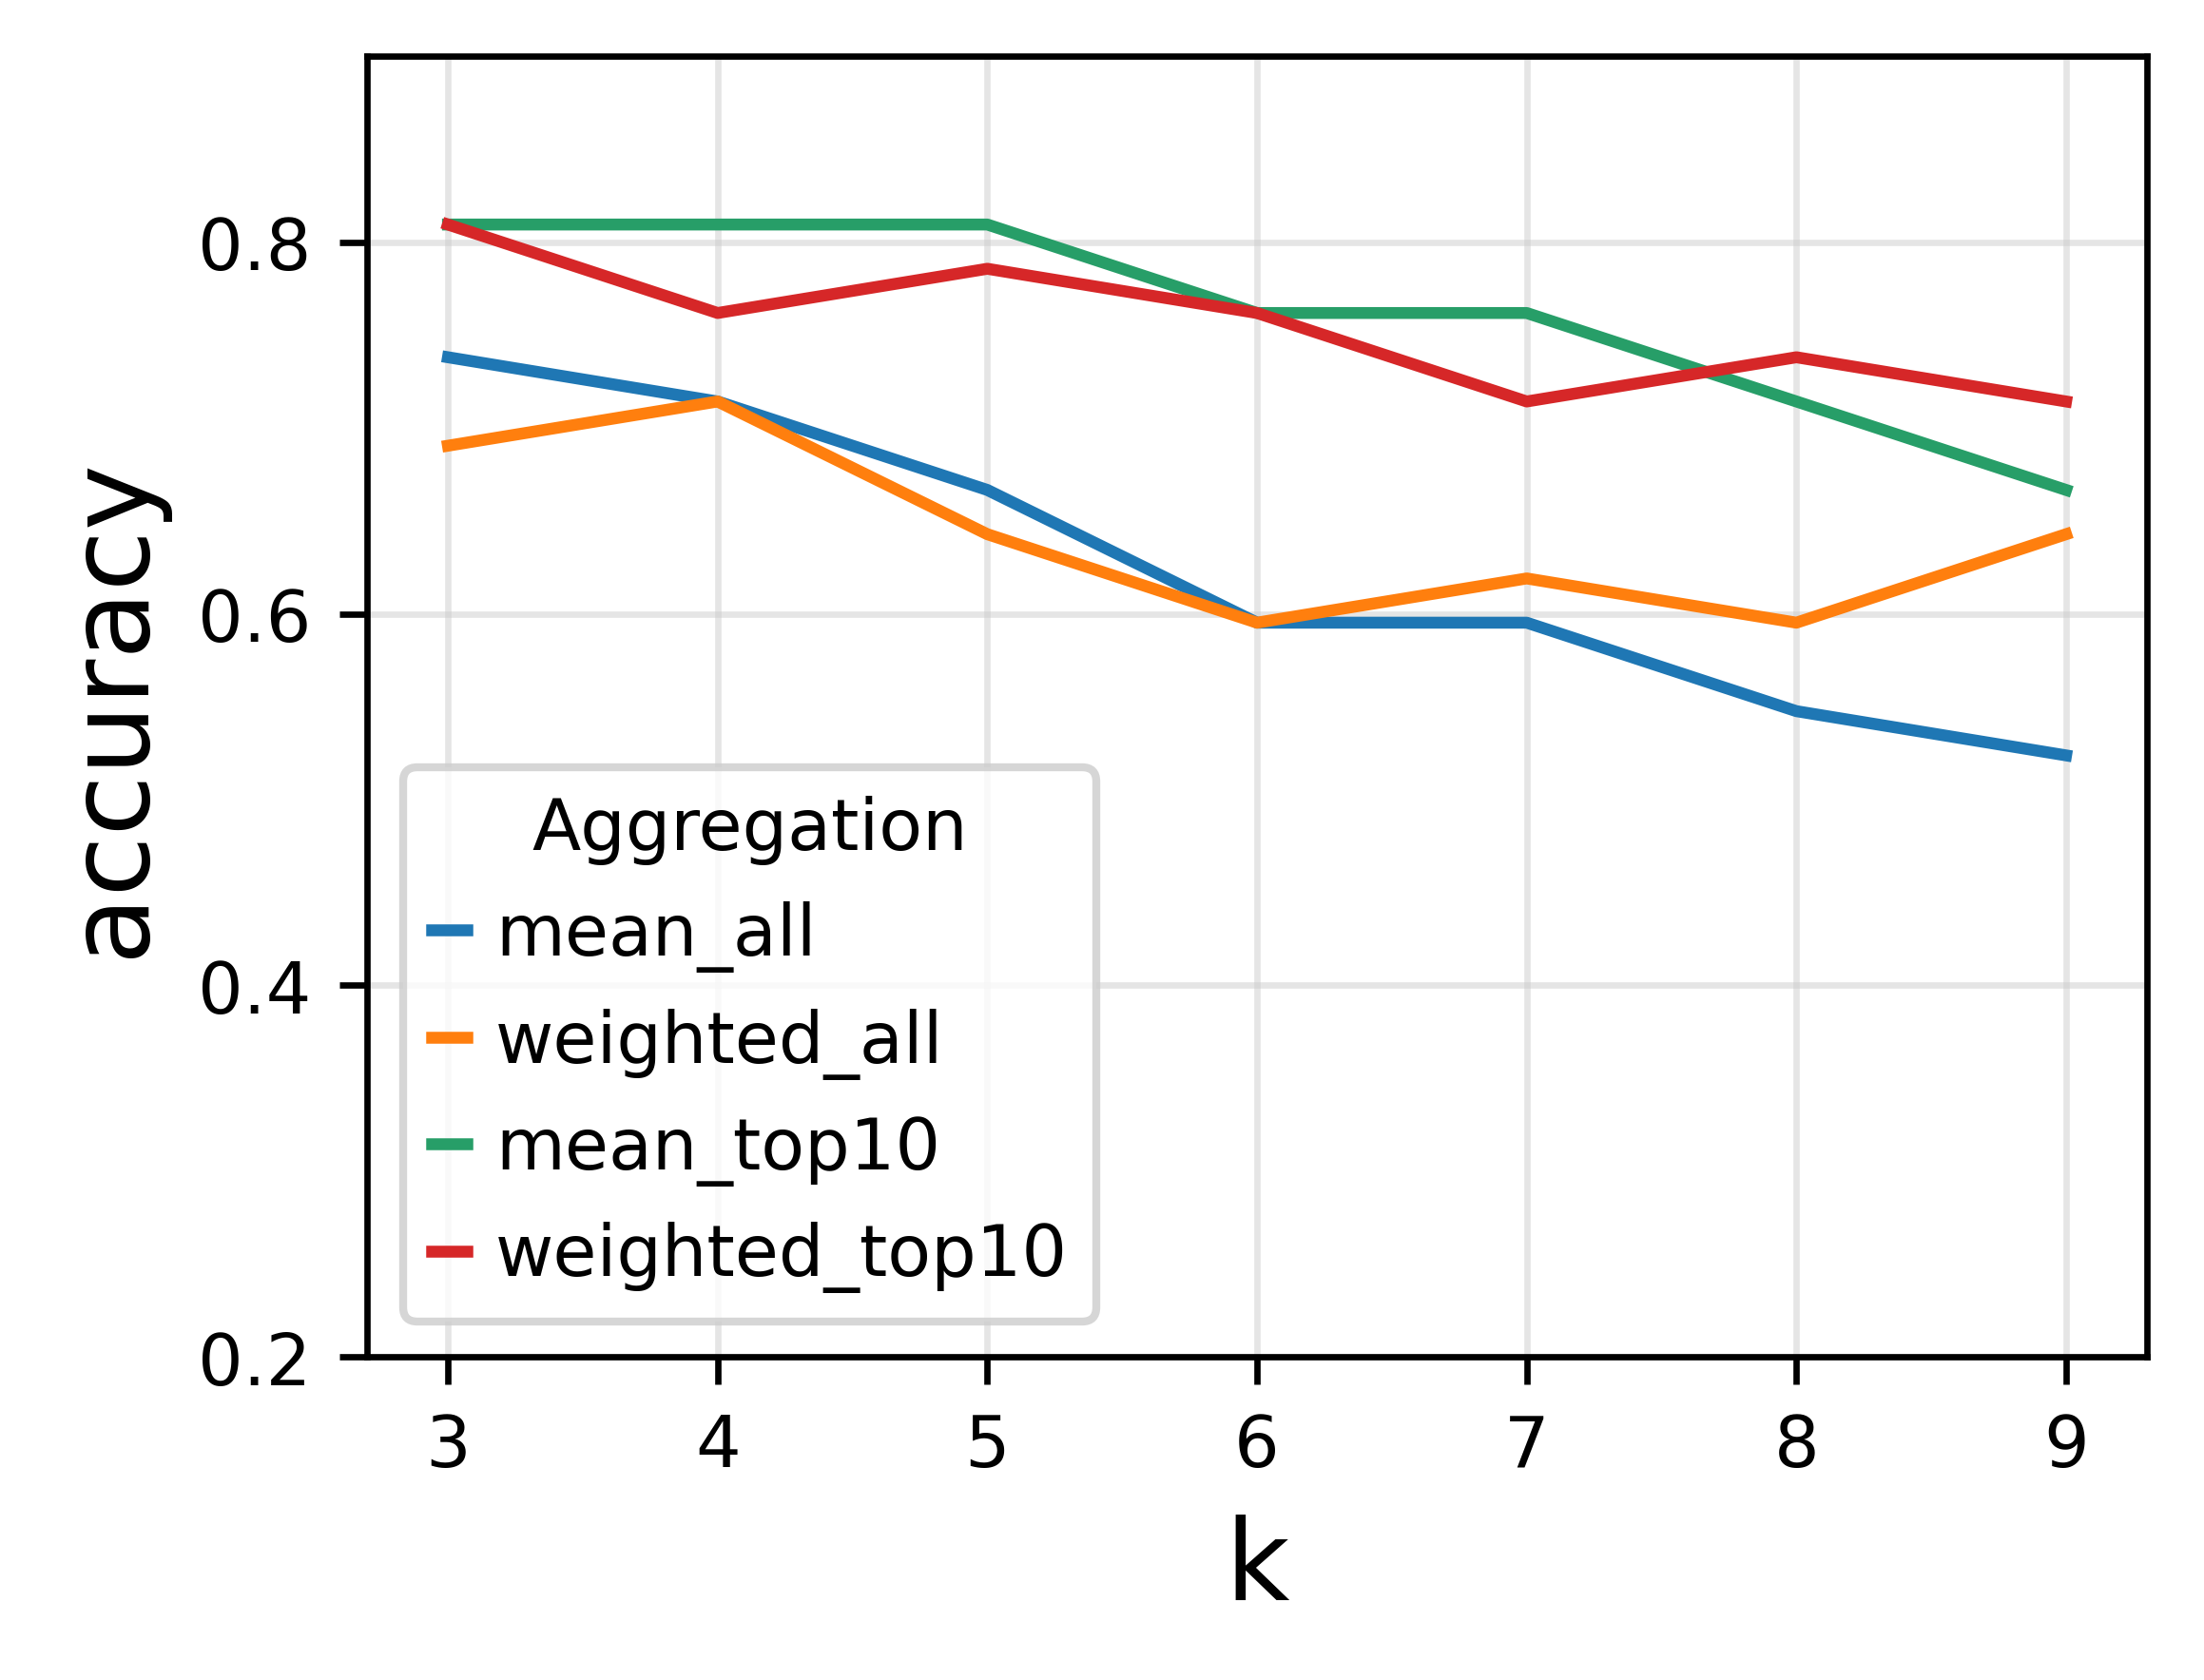

In [18]:
plt.figure(figsize=(4,3))
sns.lineplot(data=knn_df, x='k', y='accuracy', hue='agg') # marker='o'
plt.legend(title='Aggregation')
plt.ylim(0.2, 0.9)
plt.grid(True, alpha=0.5, zorder=0)
unique_k = sorted(knn_df['k'].unique())
plt.xticks(unique_k, fontsize=9)
plt.yticks(fontsize=9)
plt.legend(title='Aggregation', loc='lower left', fontsize=9, title_fontsize=9)
plt.savefig('figures/knn_accuracy.svg', bbox_inches='tight', dpi=300)